# Анализ переходов и построение сетей Петри для Windows Kernel-Power

Ноутбук адаптирует подход `censored_petri_discharge.ipynb` к журналам событий Windows. Рассматривается одна компонента — `Microsoft-Windows-Kernel-Power`.

Цели:
1. Построить локальную сеть Петри для каждого компьютера и сравнить вероятности переходов.
2. Объединить интервалы всех компьютеров и построить глобальную сеть Петри.
3. Учесть правостороннее цензурирование: отсутствие зарегистрированного отказа к концу наблюдения не считается отказом.

Визуально выводятся локальная сеть `pc_08` и глобальная сеть по всем компьютерам; результаты остальных локальных моделей сохраняются в файлы.

In [1]:
import sys
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pm4py

from IPython.display import display
from scipy import stats

_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (p for p in _candidates if (p / "src" / "data.py").exists()),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Не найден корень проекта. "
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import load_dataset, mark_sessions, build_component_log
from src import censored_petri as cp

pm4py.util.constants.SHOW_PROGRESS_BAR = False

print("Корень проекта:", ROOT)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




Корень проекта: c:\Users\lena\Desktop\diplom\EquipmentEventLogGeneration


## 1. Настройки журнала и модели

Указываются источник событий Windows, события, исключаемые из обычных активностей, и специальные маркеры начала, отказа и окончания наблюдения. `END_FAIL` обозначает наблюдаемый отказ, а `END_CENSORED` — завершение наблюдения без зарегистрированного отказа. Здесь же задаётся каталог сохранения результатов.

In [2]:
# Компонента Windows, которую анализируем
COMPONENT_SOURCE = "Microsoft-Windows-Kernel-Power"

# Событие Kernel-Power:41 используется для определения отказа,поэтому не включаем его в обычные активности компоненты
DROP_PAIRS = ("Microsoft-Windows-Kernel-Power:41",)

KEEP_EMPTY_SESSIONS = False

START = "START"
TERMINAL = "END_FAIL"
CENSOR_ACTIVITY = "END_CENSORED"

CENSOR_REASON = "censored"
REASON_LABELS = {
    CENSOR_REASON: "сессия завершилась без зарегистрированного отказа"
}

MIN_DURATION_DAYS = 1 / 86400

OUTPUT_DIR = (
    ROOT / "results" /
    f"censored_petri_{COMPONENT_SOURCE.rsplit('-', 1)[-1].lower()}"
)

print("Компонента:", COMPONENT_SOURCE)
print("Терминальное событие:", TERMINAL)
print("Цензурирование:", CENSOR_ACTIVITY)
print("Результаты будут сохранены в:", OUTPUT_DIR)

Компонента: Microsoft-Windows-Kernel-Power
Терминальное событие: END_FAIL
Цензурирование: END_CENSORED
Результаты будут сохранены в: c:\Users\lena\Desktop\diplom\EquipmentEventLogGeneration\results\censored_petri_power


## 2. Подготовка журнала и добавление `START`

Загружаются исходные события, выделяются сессии и определяется их исход. Затем из журнала выбираются события нужной компоненты. 
В начало каждой сессии добавляется `START` со временем начала сессии, после чего события сортируются по времени (в логах Kernel нет события которое обозначат старт сессии: `Microsoft-Windows-Kernel-General:12`, оно пренадлежит другой компоненте)

In [3]:

df_raw, sessions = mark_sessions(load_dataset())

print("Всего исходных событий:", len(df_raw))
print("Всего сессий:", len(sessions))
print("Исходы сессий:")
display(sessions["outcome"].value_counts(dropna=False))


component_log = build_component_log(
    df_raw,
    sessions,
    source=COMPONENT_SOURCE,
    drop_pairs=DROP_PAIRS,
    keep_empty=KEEP_EMPTY_SESSIONS,
)

if component_log.empty:
    raise ValueError(
        f"Журнал компоненты {COMPONENT_SOURCE!r} пуст. "
    )

case_keys = (
    component_log[["machine_id", "session_no", "case_id"]]
    .drop_duplicates()
)


session_starts = sessions[
    ["machine_id", "session_no", "t_start"]
].drop_duplicates(["machine_id", "session_no"])

starts = case_keys.merge(
    session_starts,
    on=["machine_id", "session_no"],
    how="left",
    validate="one_to_one",
)

if starts["t_start"].isna().any():
    missing = starts.loc[
        starts["t_start"].isna(),
        ["machine_id", "session_no", "case_id"]
    ]
    display(missing.head())
    raise ValueError(
        "Для некоторых сессий не найдено время t_start. "
        "Проверь разметку сессий в src.data."
    )

starts = starts.rename(columns={"t_start": "time"})
starts["activity"] = START
starts["seq"] = -1


starts = starts[component_log.columns]

model_log = pd.concat(
    [starts, component_log],
    ignore_index=True
)

model_log["time"] = pd.to_datetime(model_log["time"])

model_log = model_log.sort_values(
    ["case_id", "time", "seq"],
    kind="stable"
).reset_index(drop=True)

print("\nАктивности в подготовленном журнале:")
display(model_log["activity"].value_counts().head(20))

print("\nЧисло трасс:", model_log["case_id"].nunique())
print("Число строк:", len(model_log))
print("Число END_FAIL:", (model_log["activity"] == TERMINAL).sum())
print("Число END_CENSORED:", (model_log["activity"] == CENSOR_ACTIVITY).sum())

display(model_log.head(15))

Всего исходных событий: 501482
Всего сессий: 955
Исходы сессий:


outcome
CENSORED    661
FAIL        294
Name: count, dtype: int64


Активности в подготовленном журнале:


activity
566             11611
506              5011
507              4961
172              2976
105              2012
42               1084
107              1084
START             949
END_CENSORED      659
109               645
187               496
131               384
521               377
130               369
125               349
END_FAIL          290
577                95
578                32
524                10
Name: count, dtype: int64


Число трасс: 949
Число строк: 33394
Число END_FAIL: 290
Число END_CENSORED: 659


,case_id,machine_id,session_no,activity,time,seq
0,pc_01_0001,pc_01,1,START,2025-11-05 13:56:59,-1
1,pc_01_0001,pc_01,1,172,2025-11-05 13:57:02,56
2,pc_01_0001,pc_01,1,187,2025-11-05 19:44:37,429
3,pc_01_0001,pc_01,1,42,2025-11-05 19:44:38,432
4,pc_01_0001,pc_01,1,107,2025-11-05 19:44:44,433
5,pc_01_0001,pc_01,1,END_FAIL,2025-11-06 12:18:33,1000000000
6,pc_01_0002,pc_01,2,START,2025-11-06 13:56:51,-1
7,pc_01_0002,pc_01,2,172,2025-11-06 13:56:53,576
8,pc_01_0002,pc_01,2,187,2025-11-06 19:09:15,948
9,pc_01_0002,pc_01,2,42,2025-11-06 19:09:15,951


## 3. Построение интервалов с учётом цензурирования

Каждая трасса преобразуется в последовательность интервалов между последовательными состояниями. Для трасс с зарегистрированным отказом последним наблюдаемым состоянием становится `END_FAIL`. Для трасс без отказа создаётся правосторонне цензурированный интервал до `END_CENSORED` или до последнего доступного времени наблюдения.

В таблице интервалов `observed=True` означает наблюдаемый переход, `observed=False` — цензурированный интервал с неизвестным следующим состоянием.

In [ ]:
def intervals_from_windows_log(
    log,
    terminal=TERMINAL,
    censor_activity=CENSOR_ACTIVITY,
    case_id_key="case_id",
    activity_key="activity",
    timestamp_key="time",
    time_unit="D",
    min_duration=MIN_DURATION_DAYS,
):

    unit = pd.Timedelta(1, unit=time_unit)
    rows = []

    log = log.copy()
    log[timestamp_key] = pd.to_datetime(log[timestamp_key])

    log = log.sort_values(
        [case_id_key, timestamp_key],
        kind="stable"
    )

    for case_id, group in log.groupby(case_id_key, sort=False):
        activities = group[activity_key].astype(str).to_numpy()
        times = group[timestamp_key].to_numpy()
        if len(activities) == 0:
            continue
        
        # Если отказ зарегистрирован, обрезаем трассу после первого END_FAIL
        fail_idx = np.flatnonzero(activities == terminal)
        failed = len(fail_idx) > 0
        if failed:
            end_idx = fail_idx[0] + 1
            activities = activities[:end_idx]
            times = times[:end_idx]
            censor_time = None

        else:
            # Для незавершённой трассы используем время END_CENSORED
            censor_idx = np.flatnonzero(activities == censor_activity)

            if len(censor_idx) > 0:
                censor_time = times[censor_idx[-1]]
                end_idx = censor_idx[-1]
                activities = activities[:end_idx]
                times = times[:end_idx]
            else:
                censor_time = times[-1]
        if len(activities) == 0:
            continue


        keep = np.r_[
            True,
            activities[1:] != activities[:-1]
        ]

        states = activities[keep]
        entries = times[keep]


        for src, dst, t0, t1 in zip(
            states, states[1:], entries, entries[1:]
        ):
            duration = (pd.Timestamp(t1) - pd.Timestamp(t0)) / unit
            duration = float(duration)

            if not np.isfinite(duration):
                continue
            rows.append({
                "case_id": case_id,
                "src": src,
                "dst": dst,
                "duration": max(duration, min_duration),
                "observed": True,
                "reason": "",
            })

        if not failed and censor_time is not None:
            duration = (
                pd.Timestamp(censor_time) - pd.Timestamp(entries[-1])
            ) / unit

            duration = float(duration)

            if np.isfinite(duration):
                rows.append({
                    "case_id": case_id,
                    "src": states[-1],
                    "dst": None,
                    "duration": max(duration, min_duration),
                    "observed": False,
                    "reason": CENSOR_REASON,
                })

    result = pd.DataFrame(
        rows,
        columns=[
            "case_id", "src", "dst",
            "duration", "observed", "reason"
        ],
    )

    if not result.empty:
        result["duration"] = pd.to_numeric(
            result["duration"], errors="coerce"
        )
        result = result.loc[
            np.isfinite(result["duration"])
            & (result["duration"] > 0)
        ].reset_index(drop=True)

    return result


intervals = intervals_from_windows_log(model_log)

if intervals.empty:
    raise ValueError(
        "Не удалось получить интервалы. "
        "Проверь END_FAIL, END_CENSORED и содержимое model_log."
    )

censored = intervals.loc[~intervals["observed"]].copy()
completed = intervals.loc[intervals["observed"]].copy()

print("Всего интервалов:", len(intervals))
print("Завершённых интервалов:", len(completed))
print("Цензурированных интервалов:", len(censored))
print("Уникальных трасс в интервалах:", intervals["case_id"].nunique())

print("\nПримеры интервалов:")
display(intervals.head(10))

print("\nСводка по наблюдаемым переходам:")
display(
    completed.groupby(["src", "dst"])
    .agg(
        n_completed=("duration", "size"),
        min_days=("duration", "min"),
        median_days=("duration", "median"),
        max_days=("duration", "max"),
    )
    .reset_index()
    .sort_values("n_completed", ascending=False)
    .head(20)
)


Всего интервалов: 29142
Завершённых интервалов: 28483
Цензурированных интервалов: 659
Уникальных трасс в интервалах: 949

Примеры интервалов:


,case_id,src,dst,duration,observed,reason
0,pc_01_0001,START,172,0.000035,True,
1,pc_01_0001,172,187,0.241377,True,
2,pc_01_0001,187,42,0.000012,True,
3,pc_01_0001,42,107,0.000069,True,
4,pc_01_0001,107,END_FAIL,0.690150,True,
5,pc_01_0002,START,172,0.000023,True,
6,pc_01_0002,172,187,0.216921,True,
7,pc_01_0002,187,42,0.000012,True,
8,pc_01_0002,42,107,0.000116,True,
9,pc_01_0002,107,END_FAIL,0.849479,True,



Сводка по наблюдаемым переходам:


,src,dst,n_completed,min_days,median_days,max_days
69,566,506,5011,0.000012,0.000012,0.420428
52,507,566,4959,0.000012,0.000012,0.000012
49,506,566,3467,0.000012,0.000058,0.045799
70,566,507,2069,0.000012,0.009271,0.708657
47,506,507,1366,0.000012,0.000104,0.481296
43,42,107,1084,0.000012,0.000012,0.000289
66,566,172,1036,0.000012,0.000069,0.210359
37,172,507,972,0.000012,0.000075,0.644039
64,566,105,862,0.000012,0.015266,5.092616
77,START,172,797,0.000023,0.000035,0.000463


## 4. Выбор семейства распределения для каждого перехода

Для завершённых интервалов каждой пары `src → dst` сравниваются кандидаты распределений по AIC. 
Для слишком малых выборок используется экспоненциальное распределение как резервный вариант. 
Ошибки отдельных подгонок пропускаются, чтобы один неудачный кандидат не останавливал обработку всего журнала. 

В результате получаем выбранное семейство распределения и диагностическую таблицу.

In [ ]:
def select_families_safe(intervals, candidates=None):
    if candidates is None:
        candidates = cp.CANDIDATE_FAMILIES

    rows = []

    completed = intervals.loc[
        intervals["observed"]
        & intervals["dst"].notna()
    ]

    for (src, dst), group in completed.groupby(["src", "dst"]):
        x = group["duration"].to_numpy(dtype=float)
        x = x[np.isfinite(x) & (x > 0)]

        n = len(x)

        if n < 3 or np.unique(x).size < 2:
            rows.append({
                "src": src,
                "dst": dst,
                "n_completed": n,
                "family": "exponential",
                "aic": np.nan,
            })
            continue

        for kind in candidates:
            try:
                dist = cp.initial_dist(kind, x)
                rv, args, kwargs = cp.scipy_args(dist)

                log_likelihood = np.sum(
                    rv.logpdf(x, *args, **kwargs)
                )

                if not np.isfinite(log_likelihood):
                    continue

                n_params = len(cp.PARAMETERS[kind])
                aic = 2 * n_params - 2 * log_likelihood

                if not np.isfinite(aic):
                    continue

                rows.append({
                    "src": src,
                    "dst": dst,
                    "n_completed": n,
                    "family": kind,
                    "aic": float(aic),
                })

            except (
                ValueError,
                RuntimeError,
                FloatingPointError,
                OverflowError,
                ZeroDivisionError
            ):
                continue

        # Если ни одна подгонка не удалась, оставляем экспоненциальную модель как резервную и отмечаем, что AIC не рассчитан
        if not any(
            row["src"] == src
            and row["dst"] == dst
            and np.isfinite(row["aic"])
            for row in rows
        ):
            rows.append({
                "src": src,
                "dst": dst,
                "n_completed": n,
                "family": "exponential",
                "aic": np.nan,
            })

    table = pd.DataFrame(rows)

    if table.empty:
        raise ValueError(
            "Нет завершённых переходов для подбора распределений. "
            "Проверь число END_FAIL и интервалы."
        )

    table["delta_aic"] = np.nan

    valid = table["aic"].notna()
    if valid.any():
        min_aic = table.loc[valid].groupby(
            ["src", "dst"]
        )["aic"].transform("min")

        table.loc[valid, "delta_aic"] = (
            table.loc[valid, "aic"].to_numpy()
            - min_aic.to_numpy()
        )

    families = {}

    for (src, dst), group in table.groupby(["src", "dst"]):
        valid_group = group.loc[group["aic"].notna()]

        if valid_group.empty:
            families[(src, dst)] = "exponential"
        else:
            best_idx = valid_group["aic"].idxmin()
            families[(src, dst)] = table.loc[best_idx, "family"]

    return families, table


families, aic_table = select_families_safe(intervals)

print("Выбранные распределения:")
display(
    pd.DataFrame([
        {
            "src": src,
            "dst": dst,
            "family": family,
        }
        for (src, dst), family in families.items()
    ])
)

print("Сравнение распределений по ΔAIC:")
display(
    aic_table.pivot_table(
        index=["src", "dst", "n_completed"],
        columns="family",
        values="delta_aic",
    ).round(2)
)

Выбранные распределения:


,src,dst,family
0,105,109,lognormal
1,105,172,lognormal
2,105,187,weibull
3,105,42,weibull
4,105,507,exponential
...,...,...,...
75,START,105,exponential
76,START,125,gamma
77,START,172,lognormal
78,START,521,lognormal


Сравнение распределений по ΔAIC:


family                      exponential    gamma  lognormal  weibull
src   dst      n_completed                                          
105   109      13                 65.28     5.53       0.00     2.84
      172      462              1429.57  1281.44       0.00   944.05
      187      58                146.53    23.26       4.39     0.00
      42       28                 78.07     7.68       4.97     0.00
      524      6                  33.72     0.00       3.38     1.95
      566      464              2005.52    82.45       0.00    55.92
      END_FAIL 5                   5.82     0.00       2.36     0.96
107   109      12                  0.00     0.88       2.53     0.54
      187      164                21.28     8.87      31.19     0.00
      42       131                 8.59     0.00       1.53     6.82
      566      193                20.00    10.09      67.08     0.00
      END_FAIL 134                38.87    36.79       0.00    25.37
      105      64                160.96    43.92       0.00    16.40
      131      384               149.47    36.86      80.08     0.00
109   577      95                321.09    21.68       0.00   114.33
125   109      205                 5.88     0.81     116.02     0.00
      END_FAIL 3                   0.00     2.00       2.73     1.95
      521      40                 21.19     0.97       0.00     2.45
130   109      3                   0.00     1.55       1.95     1.63
      187      6                   0.00     1.70       6.49     2.00
      42       329               826.46    12.28       0.00    17.77
      END_FAIL 15                 41.60     1.35       0.00     1.28
      105      15                 28.56     0.93       0.00     0.61
131   187      7                   0.00     0.98       7.24     1.79
      END_FAIL 5                   9.18     0.97       1.35     0.00
172   109      321               406.54   168.54       0.00    95.06
      187      142                12.45     5.65      80.46     0.00
      566      41                 86.74     6.26       0.00     2.87
      END_FAIL 77                  0.00     1.79      52.39     1.74
      105      489                 0.00     0.68     205.22     1.94
      521      121                44.43    34.56       0.00    42.08
      125      209               610.48     7.31      16.42     0.00
      507      972              4224.33   211.93       0.00   121.37
187   42       320               334.88   115.11       0.00   206.66
42    107      1084              495.71   401.47       0.00   473.70
506   109      21                  5.66     0.00       2.39     1.18
      172      4                   0.00     1.15       2.88     1.49
      566      3467             5352.38  2440.85       0.00  1311.35
      END_FAIL 6                  21.70     2.11       0.00     1.37
      105      146              1145.57   206.92       0.00    92.13
      507      1366             5189.69   830.82       0.00   327.22
521   109      49                209.43    71.90       0.00    33.82
      187      18                  0.00     1.39       2.95     1.47
      42       34                 16.89     4.24       0.00     7.83
      566      69                 59.81     0.00      11.01     2.09
      END_FAIL 10                  9.45     0.00       2.00     0.22
      105      81               1317.01   131.98       0.00    49.29
524   42       3                   1.21     0.35       0.59     0.00
566   109      19                 31.30     3.76       0.00     1.77
      172      1036             4460.00  2761.11       0.00  1631.62
      187      101                 6.38     0.00      27.46     0.96
      42       238               148.87   103.02       0.00   136.00
      END_FAIL 34                107.45     8.23       0.00     2.44
      105      862              1980.61     0.00     142.72     0.97
      507      2069             3879.77     0.00     505.06   155.40
      506      5011            26102.88  2232.66       0.00  1195.6

## 5. Локальные сети Петри по компьютерам

Данные группируются по идентификатору компьютера, извлечённому из `case_id`. 
Для каждого компьютера отдельно подбираются распределения, оцениваются переходы с учётом цензурирования и строится сеть Петри.

В `pc_results` сохраняются интервалы, выбранные распределения, оценки переходов, сеть и начальная/конечная маркировки. Затем формируются сводная таблица и матрица вероятностей: строки — переходы, столбцы — компьютеры. Отсутствующая вероятность означает, что переход не был оценён для данного компьютера.

In [ ]:
intervals = intervals.copy()
intervals["pc_id"] = (
    intervals["case_id"]
    .astype(str)
    .str.extract(r"^(pc_\d+)_", expand=False)
)

pc_ids = sorted(intervals["pc_id"].dropna().unique())

print("Найдено компьютеров:", len(pc_ids))
print("Компьютеры:", pc_ids)

pc_results = {}
summary_rows = []

for pc_id in pc_ids:
    intervals_pc = intervals.loc[intervals["pc_id"] == pc_id].copy()
    families_pc, diagnostics_pc = select_families_safe(intervals_pc)
    estimates_pc, diagnostics_estimation_pc = cp.estimate_network(
        intervals_pc,
        families_pc,
        use_censoring=True,
    )

    net_pc, im_pc, fm_pc = cp.state_petri_net(
        intervals_pc,
        start=START,
        terminal=TERMINAL,
        estimates=estimates_pc,
    )

    censoring_pc = cp.censoring_summary(intervals_pc)

    pc_results[pc_id] = {
        "intervals": intervals_pc,
        "families": families_pc,
        "family_diagnostics": diagnostics_pc,
        "estimates": estimates_pc,
        "estimation_diagnostics": diagnostics_estimation_pc,
        "net": net_pc,
        "im": im_pc,
        "fm": fm_pc,
        "censoring": censoring_pc,
    }

    summary_rows.append({
        "pc_id": pc_id,
        "n_intervals": len(intervals_pc),
        "n_completed": int(intervals_pc["observed"].sum()),
        "n_censored": int((~intervals_pc["observed"]).sum()),
        "n_transitions": len(estimates_pc),
    })

summary_pc = pd.DataFrame(summary_rows).sort_values("pc_id").reset_index(drop=True)
display(summary_pc)


probability_rows = []
for pc_id, result in pc_results.items():
    for item in result["estimates"]:
        probability_rows.append({
            "pc_id": pc_id,
            "transition": item["name"],
            "src": item["src"],
            "dst": item["dst"],
            "probability": item["p"],
            "n_completed": item.get("n_completed"),
            "distribution": cp.dist_str(item["dist"]),
            "mean_days": cp.mean_time(item["dist"]),
        })

transition_probabilities_pc = pd.DataFrame(probability_rows)

print("Вероятности переходов по локальным сетям:")
display(transition_probabilities_pc.sort_values(["transition", "pc_id"]))

transition_probability_matrix = transition_probabilities_pc.pivot_table(
    index="transition",
    columns="pc_id",
    values="probability",
    aggfunc="first",
).sort_index()

print("Матрица вероятностей переходов (пусто, если переход не оценён в сети компьютера):")
display(transition_probability_matrix.round(5))


Найдено компьютеров: 14
Компьютеры: ['pc_01', 'pc_02', 'pc_03', 'pc_04', 'pc_05', 'pc_06', 'pc_07', 'pc_08', 'pc_09', 'pc_12', 'pc_13', 'pc_14', 'pc_15', 'pc_16']


,pc_id,n_intervals,n_completed,n_censored,n_transitions
0,pc_01,478,470,8,9
1,pc_02,139,93,46,3
2,pc_03,199,133,66,3
3,pc_04,173,115,58,2
4,pc_05,173,115,58,2
5,pc_06,226,153,73,3
6,pc_07,841,632,209,5
7,pc_08,927,903,24,14
8,pc_09,549,540,9,24
9,pc_12,141,129,12,22


Вероятности переходов по локальным сетям:


,pc_id,transition,src,dst,probability,n_completed,distribution,mean_days
65,pc_12,105→109,105,109,0.212736,4,exponential(mean=106.716),106.715966
87,pc_13,105→109,105,109,0.023729,5,exponential(mean=0.212403),0.212403
122,pc_14,105→109,105,109,0.000843,1,exponential(mean=0.00194444),0.001944
155,pc_15,105→109,105,109,0.055555,2,exponential(mean=0.0306423),0.030642
187,pc_16,105→109,105,109,0.005525,1,exponential(mean=0.0443866),0.044387
...,...,...,...,...,...,...,...,...
26,pc_07,START→172,START,172,1.000000,212,"lognormal(median=4.69626e-05, sigma=0.234847)",0.000048
40,pc_08,START→172,START,172,1.000000,127,"lognormal(median=2.79576e-05, sigma=0.238866)",0.000029
186,pc_15,START→172,START,172,1.000000,49,"lognormal(median=3.49164e-05, sigma=0.363336)",0.000037
85,pc_12,START→521,START,521,0.750000,9,"lognormal(median=1.35015e-05, sigma=0.288169)",0.000014


Матрица вероятностей переходов (пусто, если переход не оценён в сети компьютера):


pc_id,pc_01,pc_02,pc_03,pc_04,pc_05,pc_06,pc_07,pc_08,pc_09,pc_12,pc_13,pc_14,pc_15,pc_16
transition,,,,,,,,,,,,,,
105→109,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.21274,0.02373,0.00084,0.05556,0.00552
105→172,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.45,NaN,NaN,0.37352,NaN,0.05525
105→187,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.15295,0.13801,NaN,0.02778,0.13812
105→42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.72222,0.01105
105→507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.35,NaN,0.37850,0.36594,NaN,0.17127
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
START→105,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.08333,NaN,NaN,NaN,NaN
START→125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.00,NaN,1.00000,1.00000,NaN,1.00000
START→172,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,1.00000,NaN


## 6. Глобальная сеть Петри по объединённым журналам

Здесь используются интервалы всех компьютеров вместе. На объединённых данных заново подбираются семейства распределений, оцениваются переходы и строится одна глобальная сеть. Это не объединение уже готовых локальных сетей: модель оценивается по общей таблице интервалов. Результаты сохраняются в `global_results`.

In [7]:
families_all, diagnostics_all = select_families_safe(intervals)

estimates_all, estimation_diagnostics_all = cp.estimate_network(
    intervals,
    families_all,
    use_censoring=True,
)

net_all, im_all, fm_all = cp.state_petri_net(
    intervals,
    start=START,
    terminal=TERMINAL,
    estimates=estimates_all,
)

censoring_all = cp.censoring_summary(intervals)

global_results = {
    "intervals": intervals.copy(),
    "families": families_all,
    "family_diagnostics": diagnostics_all,
    "estimates": estimates_all,
    "estimation_diagnostics": estimation_diagnostics_all,
    "net": net_all,
    "im": im_all,
    "fm": fm_all,
    "censoring": censoring_all,
}

print("Глобальная модель по всем компьютерам")
print("Компьютеров:", intervals["pc_id"].nunique())
print("Трасс:", intervals["case_id"].nunique())
print("Интервалов:", len(intervals))
print("Переходов с оценками:", len(estimates_all))
print("Наблюдаемых интервалов:", int(intervals["observed"].sum()))
print("Цензурированных интервалов:", int((~intervals["observed"]).sum()))


Глобальная модель по всем компьютерам
Компьютеров: 14
Трасс: 949
Интервалов: 29142
Переходов с оценками: 80
Наблюдаемых интервалов: 28483
Цензурированных интервалов: 659


## 7. Визуализация локальной и глобальной сетей

Отображаются две основные сети: 
- локальная модель `pc_08` (компьютер, на котором первоначально проверялся подход) 
- глобальная модель по всем компьютерам. 

Для каждой выбирается пример цензурированной трассы, если она есть, и показывается соответствующая маркировка сети.


Локальная сеть pc_08, пример цензурированной трассы pc_08_0009: START → 172 → 109 → CENS


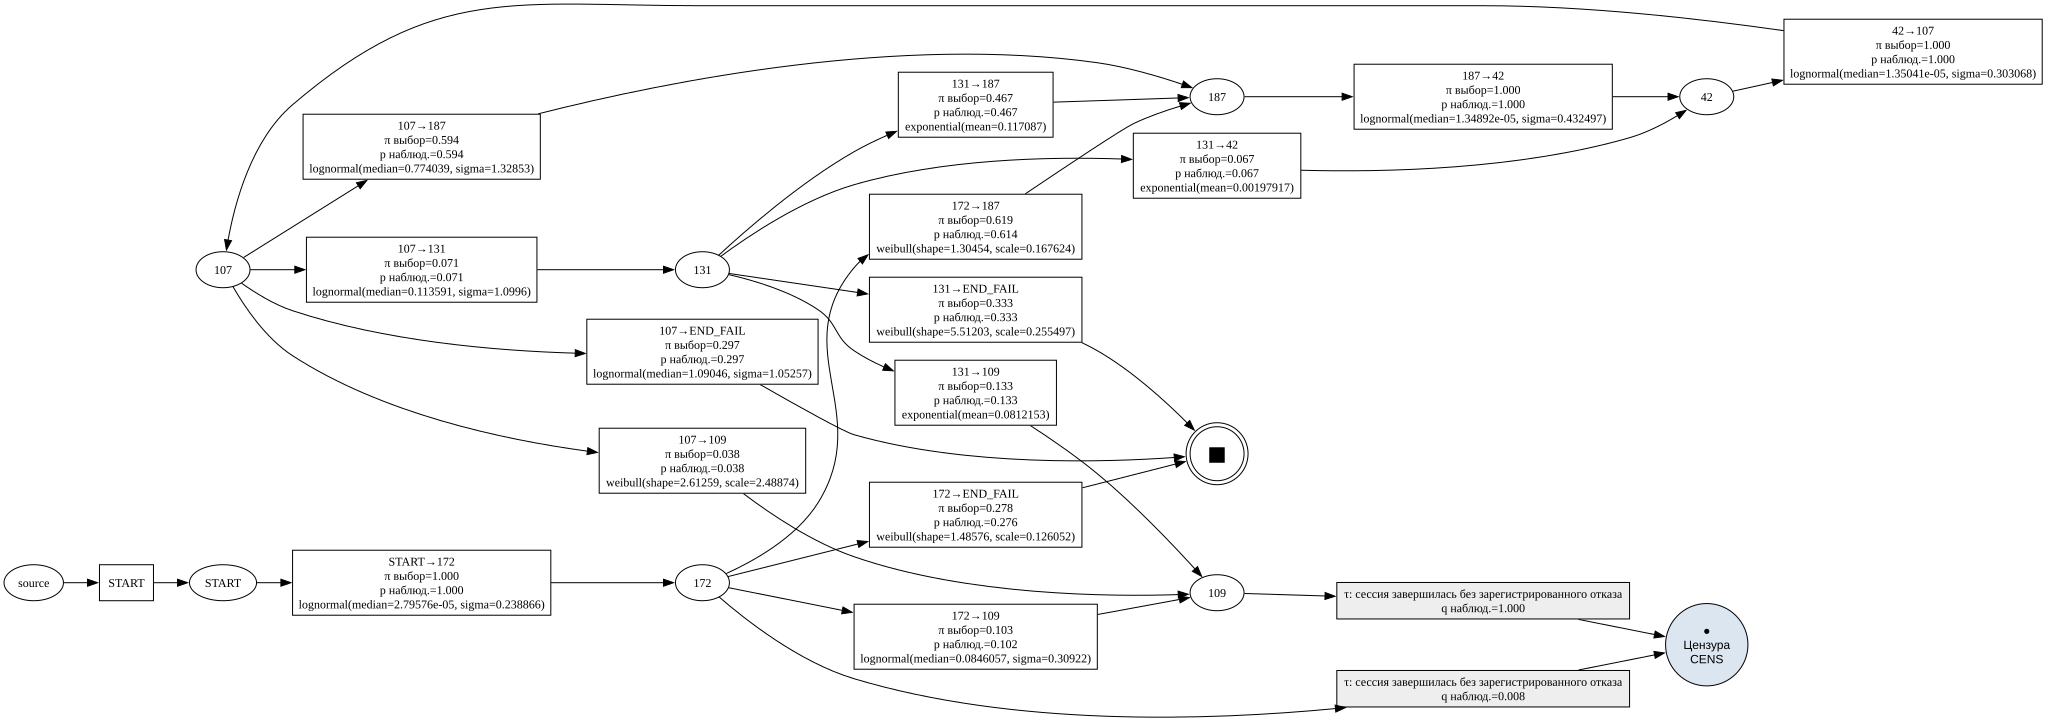

Глобальная сеть, пример цензурированной трассы pc_01_0008: START → 172 → 109 → CENS


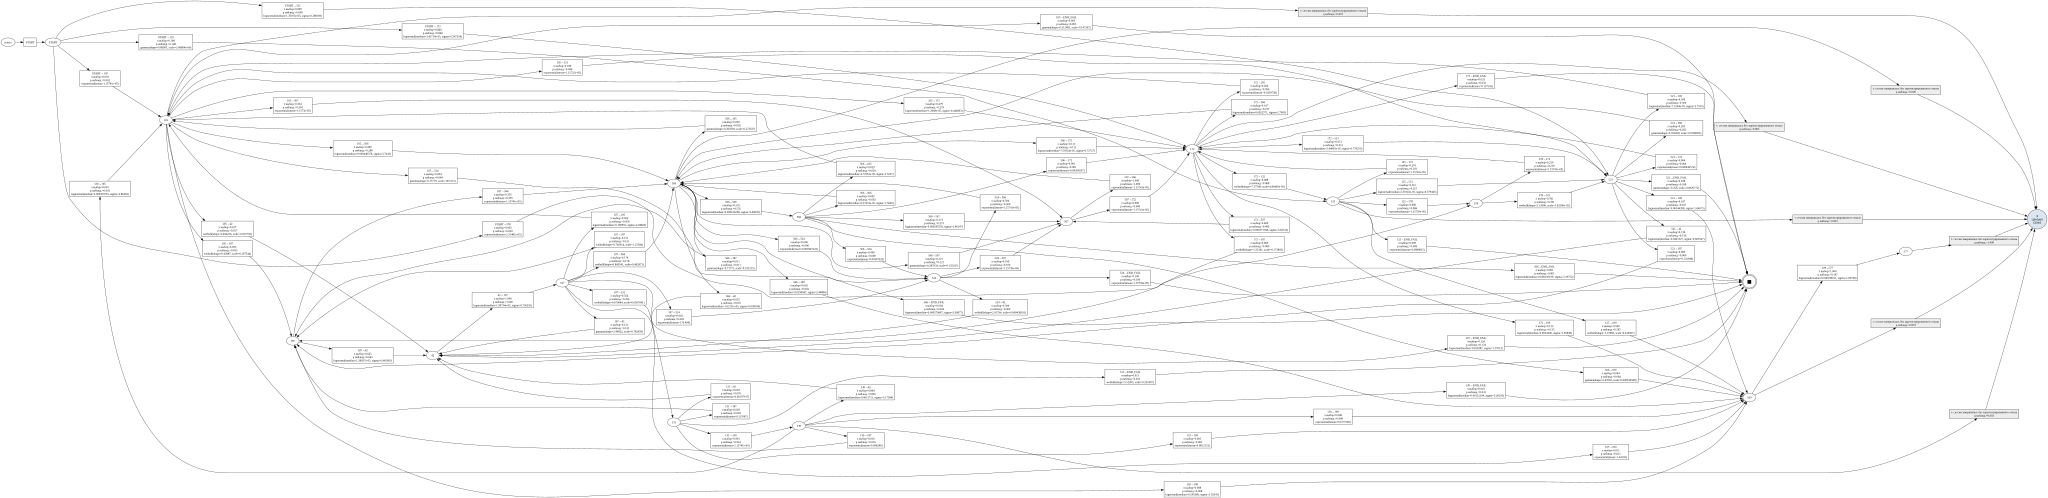

In [ ]:
def make_example_snapshot(intervals_subset, net, im, fm, label):
    censored_cases = intervals_subset.loc[
        ~intervals_subset["observed"], "case_id"
    ].drop_duplicates()

    if len(censored_cases):
        example_case = censored_cases.iloc[0]
        path = intervals_subset.loc[
            intervals_subset["case_id"] == example_case
        ].copy()

        states = [
            *path.loc[path["observed"], "src"].tolist(),
            path["src"].iloc[-1],
        ]
        marking = cp.replay_censored(
            net, im, states, reason=CENSOR_REASON
        )
        picture = cp.draw_state_net(
            net, marking, fm, reason_labels=REASON_LABELS
        )
        print(f"{label}, пример цензурированной трассы {example_case}: "
              f"{' → '.join(map(str, states))} → CENS")
    else:
        picture = cp.draw_state_net(
            net, im, fm, reason_labels=REASON_LABELS
        )
        print(f"{label}: цензурированных трасс нет; показана начальная маркировка.")

    return picture


# Локальная сеть компьютера pc_08
if "pc_08" not in pc_results:
    raise KeyError("pc_08 отсутствует в pc_results. Проверь извлечение pc_id.")

pc08_result = pc_results["pc_08"]
snapshot_pc08 = make_example_snapshot(
    pc08_result["intervals"],
    pc08_result["net"],
    pc08_result["im"],
    pc08_result["fm"],
    "Локальная сеть pc_08",
)
display(snapshot_pc08)

# Глобальная сеть по всем компьютерам
snapshot_all = make_example_snapshot(
    intervals,
    net_all,
    im_all,
    fm_all,
    "Глобальная сеть",
)
display(snapshot_all)


## 8. Дополнительный граф наблюдаемых переходов

Строится граф переходов по объединённым данным с подписью доли трасс, которые не завершились зарегистрированным отказом. 
Это вспомогательная визуализация наблюдаемой структуры переходов. 


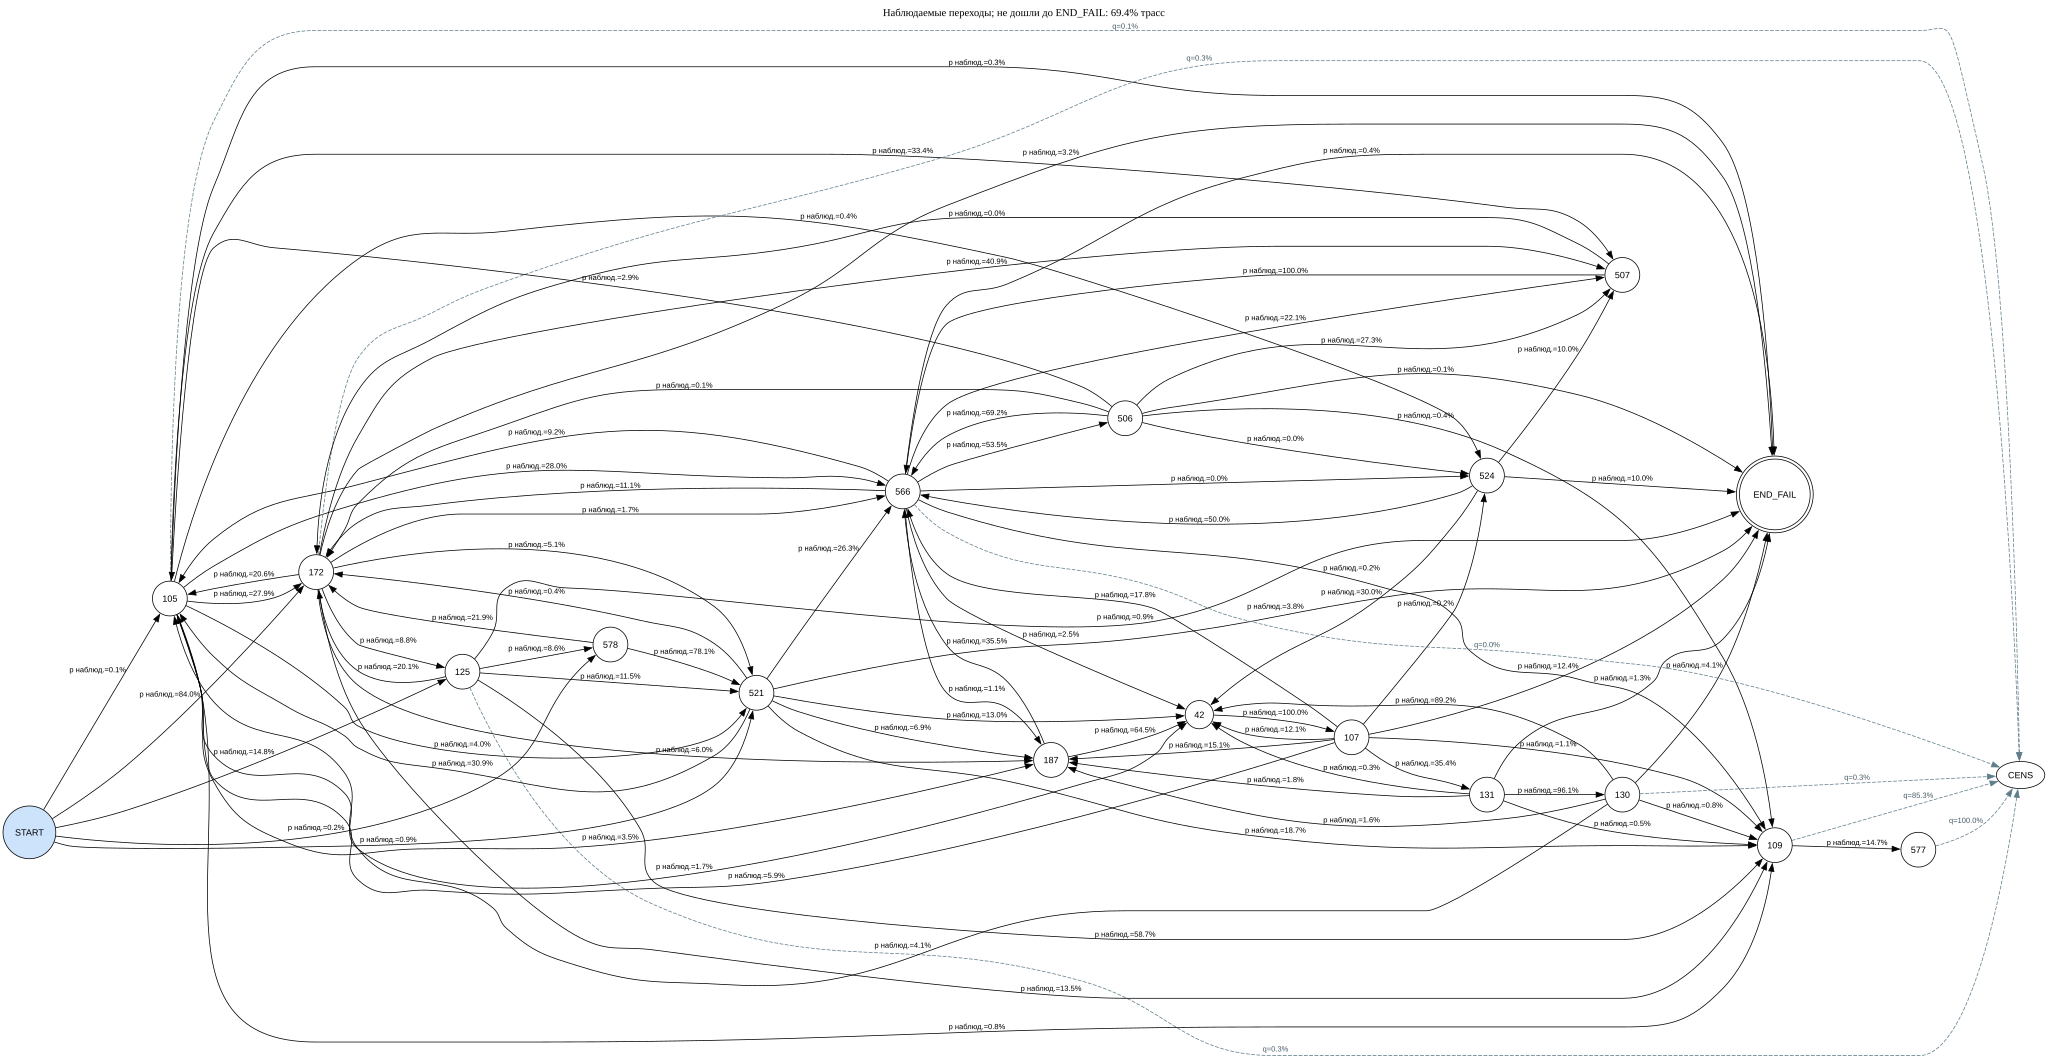

In [ ]:
censored_share_all = (
    1
    - intervals.loc[intervals["dst"] == TERMINAL, "case_id"].nunique()
      / intervals["case_id"].nunique()
)

graph_all = cp.state_graph(
    intervals,
    start=START,
    terminal=TERMINAL,
    reason_labels=REASON_LABELS,
    title=(
        f"Наблюдаемые переходы; не дошли до {TERMINAL}: "
        f"{censored_share_all:.1%} трасс"
    ),
)
display(graph_all)


## 9. Сохранение результатов

Таблицы, диагностические данные, интервалы, изображения и сериализованные объекты моделей записываются в каталог `OUTPUT_DIR` (results\censored_petri_power). Для каждого компьютера создаётся отдельная папка, а результаты глобальной модели сохраняются в подпапке `global`. 

Ячейку надо запустить после успешного выполнения всех предыдущих ячеек

In [15]:
# Сохранение результатов моделей, таблиц и изображений.
import pickle

figure_dir = Path(OUTPUT_DIR)
pc_dir = figure_dir / "per_computer"
global_dir = figure_dir / "global"
pc_dir.mkdir(parents=True, exist_ok=True)
global_dir.mkdir(parents=True, exist_ok=True)

# Сводка по локальным моделям и цензурированию.
summary_pc.to_csv(figure_dir / "summary_per_computer.csv", index=False)
transition_probabilities_pc.to_csv(
    figure_dir / "transition_probabilities_per_computer.csv", index=False
)
transition_probability_matrix.to_csv(
    figure_dir / "transition_probability_matrix.csv"
)
censoring_all.to_csv(global_dir / "censoring_summary.csv", index=False)

diagnostics_all.to_csv(global_dir / "family_aic.csv", index=False)
pd.DataFrame([
    {"src": src, "dst": dst, "family": family}
    for (src, dst), family in families_all.items()
]).to_csv(global_dir / "selected_families.csv", index=False)
estimation_diagnostics_all.to_csv(
    global_dir / "estimation_diagnostics.csv", index=False
)

# Сохраняем таблицы и диаграммы каждого компьютера.
for pc_id, result in pc_results.items():
    out_dir = pc_dir / pc_id
    out_dir.mkdir(parents=True, exist_ok=True)

    result["intervals"].to_csv(out_dir / "intervals.csv", index=False)
    result["family_diagnostics"].to_csv(
        out_dir / "family_aic.csv", index=False
    )
    pd.DataFrame([
        {"src": src, "dst": dst, "family": family}
        for (src, dst), family in result["families"].items()
    ]).to_csv(out_dir / "selected_families.csv", index=False)
    result["estimation_diagnostics"].to_csv(
        out_dir / "estimation_diagnostics.csv", index=False
    )
    pd.DataFrame(result["estimates"]).to_csv(
        out_dir / "edge_estimates.csv", index=False
    )
    result["censoring"].to_csv(out_dir / "censoring_summary.csv", index=False)

    picture = make_example_snapshot(
        result["intervals"],
        result["net"],
        result["im"],
        result["fm"],
        f"Сеть {pc_id}",
    )
    for fmt in ("png", "svg"):
        (out_dir / f"petri_{pc_id}.{fmt}").write_bytes(picture.pipe(format=fmt))

    # Сохраняем объекты модели для повторного использования в Python.
    try:
        with open(out_dir / "model.pkl", "wb") as f:
            pickle.dump(
                {
                    "families": result["families"],
                    "estimates": result["estimates"],
                    "net": result["net"],
                    "im": result["im"],
                    "fm": result["fm"],
                },
                f,
            )
    except Exception as exc:
        print(f"Не удалось сохранить pickle-модель {pc_id}: {exc}")

# Сохраняем глобальную модель и её артефакты.
intervals.to_csv(global_dir / "intervals_all.csv", index=False)
pd.DataFrame(estimates_all).to_csv(
    global_dir / "edge_estimates_with_censoring.csv", index=False
)

for name, picture in [
    ("petri_all", snapshot_all),
    ("observed_states_with_censoring", graph_all),
]:
    for fmt in ("png", "svg"):
        (global_dir / f"{name}.{fmt}").write_bytes(picture.pipe(format=fmt))

try:
    with open(global_dir / "model_all.pkl", "wb") as f:
        pickle.dump(
            {
                "families": families_all,
                "estimates": estimates_all,
                "net": net_all,
                "im": im_all,
                "fm": fm_all,
            },
            f,
        )
except Exception as exc:
    print(f"Не удалось сохранить pickle глобальной модели: {exc}")

print("Результаты сохранены в:", figure_dir.resolve())
print("Локальные модели:", pc_dir.resolve())
print("Глобальная модель:", global_dir.resolve())


Сеть pc_01, пример цензурированной трассы pc_01_0008: START → 172 → 109 → CENS
Сеть pc_02, пример цензурированной трассы pc_02_0001: START → 172 → 109 → CENS
Сеть pc_03, пример цензурированной трассы pc_03_0001: START → 172 → 109 → CENS
Сеть pc_04, пример цензурированной трассы pc_04_0001: START → 172 → 109 → CENS
Сеть pc_05, пример цензурированной трассы pc_05_0001: START → 172 → 109 → CENS
Сеть pc_06, пример цензурированной трассы pc_06_0001: START → 172 → 109 → CENS
Сеть pc_07, пример цензурированной трассы pc_07_0001: START → 172 → 125 → 109 → CENS
Сеть pc_08, пример цензурированной трассы pc_08_0009: START → 172 → 109 → CENS
Сеть pc_09, пример цензурированной трассы pc_09_0001: START → 125 → 521 → 105 → 521 → 566 → 506 → 566 → 172 → 105 → 172 → 507 → 566 → 506 → 566 → 507 → 566 → 506 → 566 → 105 → 507 → 566 → 506 → 566 → 172 → 507 → 566 → 506 → 507 → 566 → 506 → 566 → 172 → 507 → 566 → 506 → 566 → 172 → 105 → 172 → 507 → 566 → 506 → 566 → 507 → 566 → 506 → 566 → 507 → 566 → 506 → 